## Clustering: Preparación de características

Se eligen y justifican las features, se filtran actores con poca actividad, se estandariza y se reduce dimensión con PCA.

- **Se ejecuta en Spark:** son decenas de miles de proveedores y `StandardScaler`/`PCA` de MLlib escalan linealmente
- Se exporta además una **muestra local** para los métodos O(n²) (DBSCAN/HDBSCAN, jerárquico)
- Entrada: `data/artefactos/features_*` (Parte I) · Salida: `data/clustering/prep_*`, `local_*`, `config.json`

### Imports

In [1]:
import os, socket, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)

### Utilidades

- Constantes

In [2]:
SECCION, NOTEBOOK = "02_Clustering", "a_preparacion"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

final_dir = proyecto / "data" / "final"
artef_dir = proyecto / "data" / "artefactos"
clus_dir  = proyecto / "data" / "clustering"
clus_dir.mkdir(parents=True, exist_ok=True)
SUJETOS = {"entidad": "entidad_key", "proveedor": "proveedor_key"}
SEED = 42

out_dir = proyecto / SECCION / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima")
           .config("spark.sql.execution.arrow.pyspark.enabled", "true"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### 1. Carga

In [5]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.functions import vector_to_array

base = {
    "entidad": leer(artef_dir, "features_entidad")
               .join(leer(final_dir, "entidades").select("entidad_key", "nombre"), "entidad_key", "left"),
    "proveedor": leer(artef_dir, "features_proveedor")
               .join(leer(final_dir, "proveedores").select("proveedor_key", "nombre", "region", "tipo", "es_consorcio"),
                     "proveedor_key", "left"),
}
for s, df in base.items():
    print(f"{s:10s}: {df.count():,} filas")

entidad   : 2,995 filas
proveedor : 35,638 filas


### 2. Selección de características

Qué patrón se busca: **tipologías de comportamiento de compra/venta** y **actores atípicos** (PQ1: concentración y
cautividad). Por eso las features describen volumen, competencia, dependencia y diversidad, no identidad.

| Sujeto | Feature | Qué captura |
|---|---|---|
| ambos | `log_n_procesos`, `log_monto_mediano` | Volumen y tamaño típico (log por cola pesada) |
| ambos | `pct_postor_unico`, `pct_directa` | Competencia (hallazgo central del P1) |
| ambos | `pct_bienes`, `pct_obras` | Mezcla de categoría (`pct_servicios` = 1 − ambas → se omite) |
| ambos | `log_n_familias` | Diversidad de rubros |
| entidad | `share_top_proveedor`, `log_n_proveedores` | Dependencia de un proveedor |
| entidad | `log_postores_promedio`, `pct_sin_adjudicar` | Competencia promedio y procesos desiertos |
| proveedor | `share_top_entidad`, `log_n_entidades`, `n_regiones` | Dependencia de un cliente y alcance |
| proveedor | `pct_consorcio`, `tasa_exito`, `compite` | Forma de participar |

**Descartadas a propósito:** `log_monto_total` (≈ `log_n_procesos` + `log_monto_mediano`), `hhi_*` (redundante con
`share_top_*`), `meses_activos` (redundante con `n_procesos`), `pct_servicios` (combinación lineal). Las variables
redundantes duplican el peso de un mismo concepto en la distancia euclidiana.

In [6]:
FEAT = {
    "entidad":   ["log_n_procesos", "log_monto_mediano", "pct_postor_unico", "pct_directa", "log_postores_promedio",
                  "pct_sin_adjudicar", "pct_bienes", "pct_obras", "share_top_proveedor", "log_n_proveedores", "log_n_familias"],
    "proveedor": ["log_n_procesos", "log_n_entidades", "n_regiones", "log_monto_mediano", "pct_postor_unico", "pct_directa",
                  "pct_consorcio", "pct_bienes", "pct_obras", "share_top_entidad", "log_n_familias", "tasa_exito", "compite"],
}
META = {
    "entidad":   ["entidad_key", "nombre", "region", "n_procesos", "monto_adjudicado_total", "n_proveedores", "hhi_proveedores"],
    "proveedor": ["proveedor_key", "nombre", "region", "tipo", "es_consorcio", "n_procesos", "monto_total", "n_entidades", "hhi_entidades"],
}
MIN_PROCESOS = {"entidad": 5, "proveedor": 3}
VAR_OBJ, N_LOCAL = 0.85, 10_000

# tasa de éxito: quien nunca compite no tiene tasa 0 sino "no aplica" -> mediana de los que compiten (+ flag `compite`)
med_tasa = base["proveedor"].where("compite = 1").approxQuantile("tasa_exito", [0.5], 0.01)[0]
derivadas = {
    "entidad": {"log_n_proveedores": F.log1p(F.coalesce("n_proveedores", F.lit(0))),
                "log_n_familias": F.log1p(F.coalesce("n_familias", F.lit(0))),
                "log_postores_promedio": F.log1p(F.coalesce("postores_promedio", F.lit(0)))},
    "proveedor": {"log_n_entidades": F.log1p("n_entidades"),
                  "log_n_familias": F.log1p(F.coalesce("n_familias", F.lit(0))),
                  "tasa_exito": F.when(F.col("compite") == 0, F.lit(med_tasa)).otherwise(F.col("tasa_exito"))},
}

filtrados, resumen = {}, []
for s, df in base.items():
    for c, expr in derivadas[s].items():
        df = df.withColumn(c, expr)
    df = df.fillna(0, FEAT[s])
    n0 = df.count()
    df = df.where(F.col("n_procesos") >= MIN_PROCESOS[s]).cache()
    filtrados[s] = df
    resumen.append((s, n0, df.count(), MIN_PROCESOS[s]))
resumen_filtro = pd.DataFrame(resumen, columns=["sujeto", "total", "en_clustering", "min_procesos"])
resumen_filtro["pct_excluido"] = (100 * (1 - resumen_filtro.en_clustering / resumen_filtro.total)).round(1)
print(f"mediana tasa de éxito (imputación): {med_tasa:.3f}")
resumen_filtro

mediana tasa de éxito (imputación): 0.500


,sujeto,total,en_clustering,min_procesos,pct_excluido
0,entidad,2995,2695,5,10.0
1,proveedor,35638,5865,3,83.5


- **Filtro de actividad:** con 1-2 procesos, `share_top_*` vale 1 y los porcentajes son 0 o 1 → miles de puntos idénticos
  que forman un "clúster" artificial. Se excluyen del clustering (no del análisis): son los actores esporádicos
- ‹pct_excluido›% de proveedores queda fuera: se reporta aparte como segmento "esporádico"

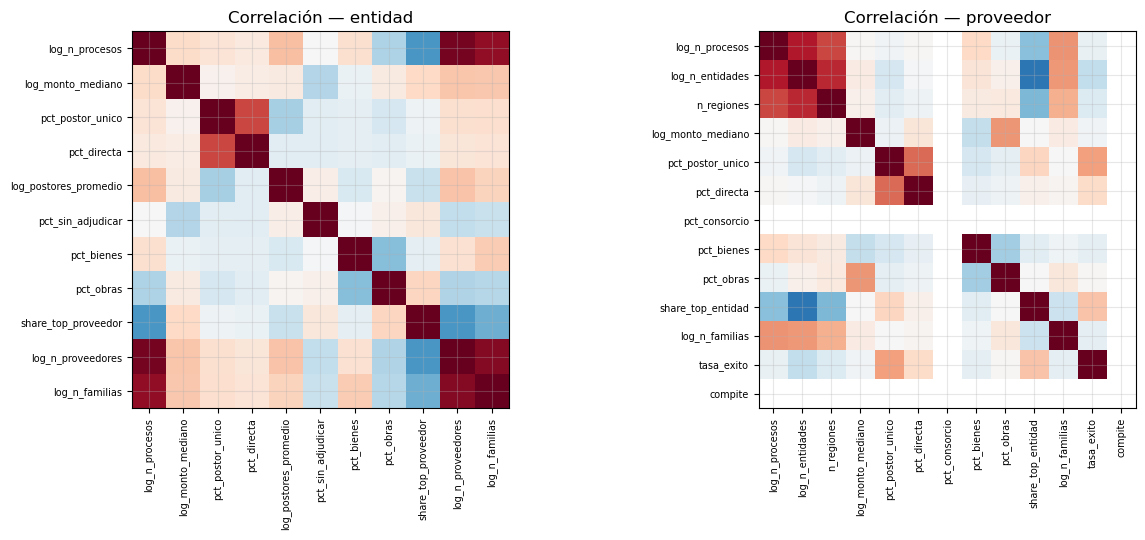

entidad pares |r| > 0.85: [('log_n_procesos', 'log_n_proveedores', 0.96), ('log_n_procesos', 'log_n_familias', 0.88), ('log_n_proveedores', 'log_n_familias', 0.92)]
proveedor pares |r| > 0.85: ninguno


In [7]:
corrs = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for i, (s, df) in enumerate(filtrados.items()):
    n = df.count()
    m = df.select(FEAT[s]).sample(fraction=min(1.0, 20_000 / n), seed=SEED).toPandas().corr()
    corrs[s] = m
    ax[i].imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    ax[i].set_xticks(range(len(m))); ax[i].set_xticklabels(m.columns, rotation=90, fontsize=7)
    ax[i].set_yticks(range(len(m))); ax[i].set_yticklabels(m.columns, fontsize=7)
    ax[i].set_title(f"Correlación — {s}")
mostrar_fig("correlaciones")

for s, m in corrs.items():
    altos = [(a, b, round(m.loc[a, b], 2)) for i, a in enumerate(m.columns) for b in m.columns[i + 1:] if abs(m.loc[a, b]) > 0.85]
    print(s, "pares |r| > 0.85:", altos or "ninguno")

- Si aparece algún par con |r| > 0.85, se retira una de las dos variables de `FEAT` y se vuelve a correr
- Correlaciones moderadas (0.5–0.85) se toleran: el PCA siguiente las absorbe en componentes comunes

---
### 3. Estandarización y PCA

entidad: 11 features -> 6 componentes (89.0% de varianza)
proveedor: 13 features -> 7 componentes (88.8% de varianza)


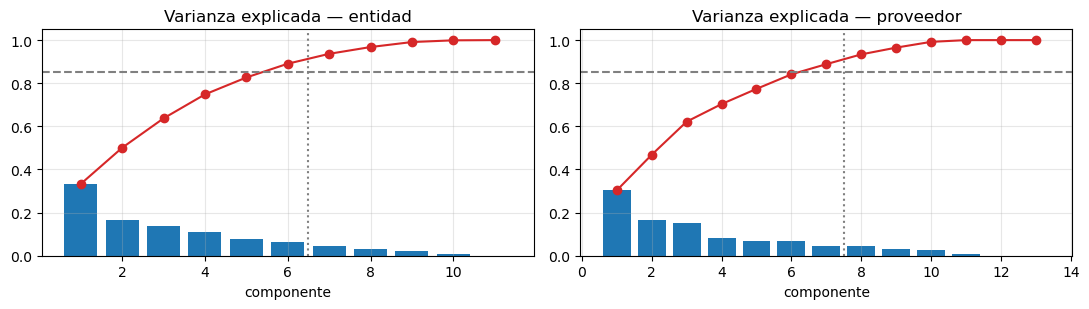

--- cargas PC1/PC2 — entidad


componente,1,2
feature,,
log_n_proveedores,-0.51,0.05
log_n_procesos,-0.49,0.10
log_n_familias,-0.49,0.03
share_top_proveedor,0.34,-0.12
pct_obras,0.22,0.10
log_postores_promedio,-0.15,0.42
pct_sin_adjudicar,0.13,0.19
pct_bienes,-0.13,0.05
log_monto_mediano,-0.12,-0.08


--- cargas PC1/PC2 — proveedor


componente,1,2
feature,,
log_n_entidades,-0.52,0.08
log_n_procesos,-0.45,0.12
n_regiones,-0.44,0.11
share_top_entidad,0.40,0.05
log_n_familias,-0.30,0.23
tasa_exito,0.19,0.31
pct_postor_unico,0.17,0.48
pct_bienes,-0.11,-0.38
pct_directa,0.08,0.48


In [8]:
config, varianza, cargas, escalado, prep = {}, [], [], [], {}
for s, df in filtrados.items():
    feats, key = FEAT[s], SUJETOS[s]
    d = VectorAssembler(inputCols=feats, outputCol="x").transform(df)
    scm = StandardScaler(inputCol="x", outputCol="features_std", withMean=True, withStd=True).fit(d)
    d = scm.transform(d)
    var = PCA(k=len(feats), inputCol="features_std", outputCol="_p").fit(d).explainedVariance.toArray()
    acum = np.cumsum(var)
    n_comp = max(2, int(np.searchsorted(acum, VAR_OBJ) + 1))
    pca = PCA(k=n_comp, inputCol="features_std", outputCol="pca").fit(d)
    d = (pca.transform(d).withColumn("_pa", vector_to_array("pca"))
            .withColumn("pc1", F.col("_pa")[0]).withColumn("pc2", F.col("_pa")[1]))
    cols = [key] + [c for c in META[s] if c != key] + feats + ["features_std", "pca", "pc1", "pc2"]
    d.select(*cols).write.mode("overwrite").parquet(str(clus_dir / f"prep_{s}"))
    prep[s] = leer(clus_dir, f"prep_{s}")

    config[s] = {"key": key, "feats": feats, "n_comp": n_comp}
    varianza += [(s, i + 1, float(v), float(acum[i])) for i, v in enumerate(var)]
    pc = pca.pc.toArray()
    cargas += [(s, f, j + 1, float(pc[i, j])) for i, f in enumerate(feats) for j in range(n_comp)]
    escalado += [(s, f, float(m), float(sd)) for f, m, sd in zip(feats, scm.mean.toArray(), scm.std.toArray())]
    print(f"{s}: {len(feats)} features -> {n_comp} componentes ({acum[n_comp - 1]:.1%} de varianza)")

(clus_dir / "config.json").write_text(json.dumps(config, indent=1))
varianza = pd.DataFrame(varianza, columns=["sujeto", "componente", "varianza", "acumulada"])
cargas = pd.DataFrame(cargas, columns=["sujeto", "feature", "componente", "carga"])
escalado = pd.DataFrame(escalado, columns=["sujeto", "feature", "media", "desv"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, s in enumerate(config):
    v = varianza[varianza.sujeto == s]
    ax[i].bar(v.componente, v.varianza); ax[i].plot(v.componente, v.acumulada, "o-", color="tab:red")
    ax[i].axhline(VAR_OBJ, ls="--", color="grey"); ax[i].axvline(config[s]["n_comp"] + .5, ls=":", color="grey")
    ax[i].set_title(f"Varianza explicada — {s}"); ax[i].set_xlabel("componente")
mostrar_fig("varianza_pca")

for s in config:
    print(f"--- cargas PC1/PC2 — {s}")
    display(cargas[(cargas.sujeto == s) & (cargas.componente <= 2)]
            .pivot(index="feature", columns="componente", values="carga").round(2)
            .sort_values(1, key=abs, ascending=False))

- **Estandarización:** KMeans y DBSCAN usan distancia euclidiana; sin escalar, `log_monto` (≈ 12) dominaría a los porcentajes (0–1)
- **PCA al 85%:** quita ruido y redundancia y estabiliza las distancias. Las cargas de PC1/PC2 dicen qué ejes
  organizan el espacio (‹p. ej. PC1 = volumen, PC2 = competencia›)
- `pc1`/`pc2` se guardan para graficar y para la web

---
### 4. Muestra local para métodos O(n²)

In [9]:
for s, d in prep.items():
    key, feats, n_comp = config[s]["key"], config[s]["feats"], config[s]["n_comp"]
    n = d.count()
    m = d.sample(fraction=min(1.0, N_LOCAL / n), seed=SEED) if n > N_LOCAL else d
    (m.withColumn("_z", vector_to_array("features_std")).withColumn("_pa", vector_to_array("pca"))
      .select(key, *[c for c in META[s] if c != key],
              *[F.col("_z")[i].alias(f"std_{f}") for i, f in enumerate(feats)],
              *[F.col("_pa")[i].alias(f"pc_{i}") for i in range(n_comp)])
      .coalesce(1).write.mode("overwrite").parquet(str(clus_dir / f"local_{s}")))
    print(f"{s}: muestra local {leer(clus_dir, f'local_{s}').count():,} de {n:,}")

entidad: muestra local 2,695 de 2,695
proveedor: muestra local 5,865 de 5,865


- **Entidades:** todas (unas pocas miles caben en local)
- **Proveedores:** muestra aleatoria de hasta 10 000. DBSCAN/HDBSCAN necesitan vecinos de cada punto, y el jerárquico la
  matriz de distancias completa (n² / 2): con 60 000 puntos serían 1 800 millones de distancias (~14 GB)

### 5. Escritura de resultados

In [10]:
corr_largo = pd.concat([m.stack().rename("r").reset_index().rename(columns={"level_0": "a", "level_1": "b"}).assign(sujeto=s)
                        for s, m in corrs.items()])
tablas = {"resumen_filtro": resumen_filtro, "varianza_pca": varianza, "cargas_pca": cargas,
          "escalado": escalado, "correlaciones": corr_largo}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en {SECCION}/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 02_Clustering/temp/a_preparacion/: resumen_filtro, varianza_pca, cargas_pca, escalado, correlaciones


#### a. Verificación

In [11]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"
figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 5 tablas (parquet + json) | 2 figuras: correlaciones, varianza_pca


---
### 6. Cerrar sesión

In [12]:
spark.stop()